In [1]:
import pandas as pd, numpy as np, os, warnings
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from statsmodels.tsa.holtwinters import ExponentialSmoothing
warnings.filterwarnings("ignore")

monthly = pd.read_csv("../outputs/reports/monthly_kpis.csv", parse_dates=["month"]).sort_values("month")
y = monthly.set_index("month")["revenue"]
y = y[y.index < "2011-12-01"].asfreq("MS")      # drop incomplete Dec 2011

print("Months used:", len(y), "|", y.index.min().date(), "to", y.index.max().date())
print("Missing values:", y.isna().sum())
y.tail()


Months used: 24 | 2009-12-01 to 2011-11-01
Missing values: 0


month
2011-07-01     718076.121
2011-08-01     757841.380
2011-09-01    1056435.192
2011-10-01    1151263.730
2011-11-01    1503866.780
Freq: MS, Name: revenue, dtype: float64

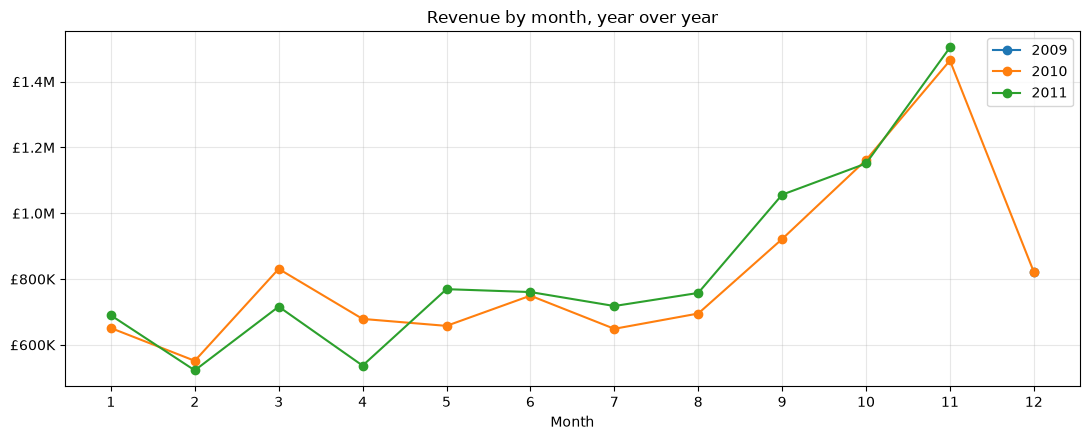

In [2]:
gbp = mtick.FuncFormatter(lambda x, _: f"£{x/1e6:.1f}M" if x >= 1e6 else f"£{x/1e3:.0f}K")

fig, ax = plt.subplots(figsize=(11, 4.5))
for yr, g in y.groupby(y.index.year):
    ax.plot(g.index.month, g.values, marker="o", label=str(yr))
ax.set_xticks(range(1, 13)); ax.set_xlabel("Month"); ax.legend()
ax.yaxis.set_major_formatter(gbp); ax.grid(alpha=.3)
ax.set_title("Revenue by month, year over year")
plt.tight_layout()
os.makedirs("../outputs/charts", exist_ok=True)
plt.savefig("../outputs/charts/08_seasonality.png", dpi=150); plt.show()


In [3]:
def mape(actual, pred):
    actual, pred = np.array(actual, float), np.array(pred, float)
    return np.mean(np.abs((actual - pred) / actual)) * 100

def mae(actual, pred):
    return np.mean(np.abs(np.array(actual, float) - np.array(pred, float)))

def forecast_model(name, series, h):
    """Return (forecast Series, residual std) for the named model."""
    idx = pd.date_range(series.index[-1] + pd.offsets.MonthBegin(1), periods=h, freq="MS")
    if name == "Seasonal naive (same month last year)":
        vals = [series.get(d - pd.DateOffset(years=1), np.nan) for d in idx]
        resid = (series - series.shift(12)).dropna()
        return pd.Series(vals, index=idx), resid.std()
    if name == "Holt-Winters (additive trend + season)":
        m = ExponentialSmoothing(series, trend="add", seasonal="add", seasonal_periods=12,
                                 initialization_method="estimated").fit()
    elif name == "Holt-Winters (damped trend + season)":
        m = ExponentialSmoothing(series, trend="add", damped_trend=True, seasonal="add",
                                 seasonal_periods=12, initialization_method="estimated").fit()
    elif name == "Damped trend (no season)":
        m = ExponentialSmoothing(series, trend="add", damped_trend=True,
                                 initialization_method="estimated").fit()
    fc = pd.Series(m.forecast(h).values, index=idx)
    return fc, (series - m.fittedvalues).std()

models = ["Seasonal naive (same month last year)",
          "Holt-Winters (additive trend + season)",
          "Holt-Winters (damped trend + season)",
          "Damped trend (no season)"]


In [4]:
H = 4
train, test = y.iloc[:-H], y.iloc[-H:]

rows = []
for name in models:
    try:
        fc, _ = forecast_model(name, train, H)
        rows.append({"model": name, "MAPE_%": mape(test, fc), "MAE_£": mae(test, fc)})
    except Exception as e:
        rows.append({"model": name, "MAPE_%": np.nan, "MAE_£": np.nan})
        print("Failed:", name, "->", e)

results = pd.DataFrame(rows).sort_values("MAPE_%").reset_index(drop=True)
os.makedirs("../outputs/reports", exist_ok=True)
results.to_csv("../outputs/reports/forecast_model_comparison.csv", index=False)
results


Failed: Holt-Winters (additive trend + season) -> Cannot compute initial seasonals using heuristic method with less than two full seasonal cycles in the data.
Failed: Holt-Winters (damped trend + season) -> Cannot compute initial seasonals using heuristic method with less than two full seasonal cycles in the data.


,model,MAPE_%,MAE_£
0,Seasonal naive (same month last year),6.142122,61884.949750
1,Damped trend (no season),27.000006,342192.310504
2,Holt-Winters (additive trend + season),NaN,NaN
3,Holt-Winters (damped trend + season),NaN,NaN


In [5]:
best = results.loc[results["MAPE_%"].idxmin(), "model"]
best_mape = results["MAPE_%"].min()
print("Best model:", best, "| back-test MAPE: {:.1f}%".format(best_mape))

fc, sd = forecast_model(best, y, 6)
z = 1.28                                    # approx. 80% interval (10th to 90th percentile)
out = pd.DataFrame({"month": fc.index, "forecast": fc.values,
                    "lower_80": (fc - z * sd).clip(lower=0).values,
                    "upper_80": (fc + z * sd).values})
out["model"] = best
out["backtest_mape_pct"] = best_mape

os.makedirs("../data/processed", exist_ok=True)
out.to_csv("../outputs/reports/revenue_forecast.csv", index=False)
out.to_csv("../data/processed/revenue_forecast.csv", index=False)
print("6-Month Total Forecasted Revenue: £{:,.2f}".format(out["forecast"].sum()))
out


Best model: Seasonal naive (same month last year) | back-test MAPE: 6.1%
6-Month Total Forecasted Revenue: £4,056,290.26


,month,forecast,lower_80,upper_80,model,backtest_mape_pct
0,2011-12-01,821452.730,716228.706308,926676.753692,Seasonal naive (same month last year),6.142122
1,2012-01-01,689811.610,584587.586308,795035.633692,Seasonal naive (same month last year),6.142122
2,2012-02-01,522545.560,417321.536308,627769.583692,Seasonal naive (same month last year),6.142122
3,2012-03-01,716215.260,610991.236308,821439.283692,Seasonal naive (same month last year),6.142122
4,2012-04-01,536968.491,431744.467308,642192.514692,Seasonal naive (same month last year),6.142122
5,2012-05-01,769296.610,664072.586308,874520.633692,Seasonal naive (same month last year),6.142122


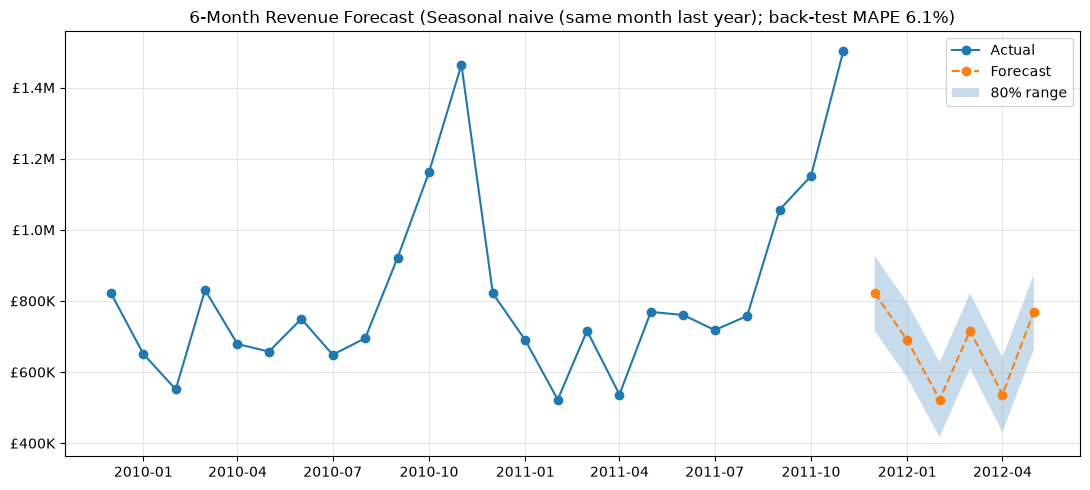

In [6]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(y.index, y.values, marker="o", label="Actual")
ax.plot(out["month"], out["forecast"], marker="o", linestyle="--", label="Forecast")
ax.fill_between(out["month"], out["lower_80"], out["upper_80"], alpha=.25, label="80% range")
ax.yaxis.set_major_formatter(gbp); ax.grid(alpha=.3); ax.legend()
ax.set_title(f"6-Month Revenue Forecast ({best}; back-test MAPE {best_mape:.1f}%)")
plt.tight_layout(); plt.savefig("../outputs/charts/09_revenue_forecast.png", dpi=150); plt.show()


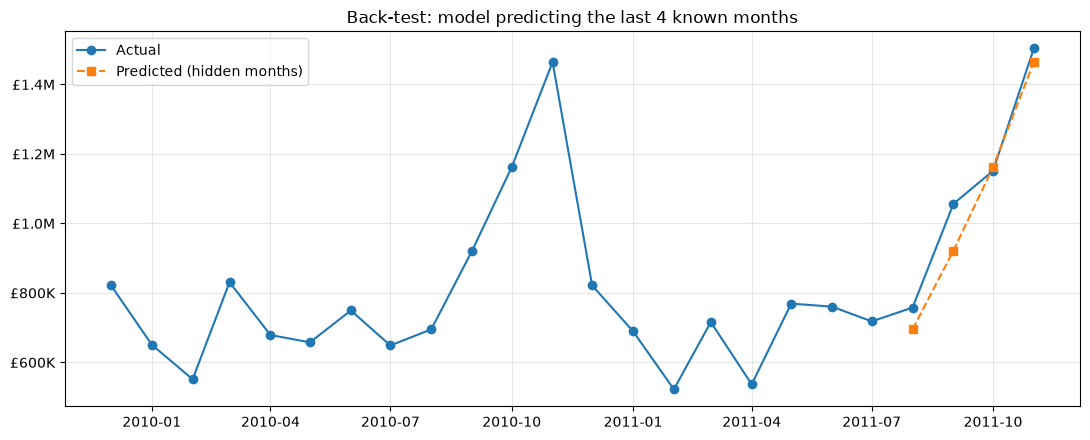

In [7]:
fc_bt, _ = forecast_model(best, train, H)
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(y.index, y.values, marker="o", label="Actual")
ax.plot(fc_bt.index, fc_bt.values, marker="s", linestyle="--", label="Predicted (hidden months)")
ax.yaxis.set_major_formatter(gbp); ax.grid(alpha=.3); ax.legend()
ax.set_title("Back-test: model predicting the last 4 known months")
plt.tight_layout(); plt.savefig("../outputs/charts/10_forecast_backtest.png", dpi=150); plt.show()
